# 12 · Gerchberg–Saxton phase retrieval: build it step by step

Intensity measurements do not directly reveal optical phase. The Gerchberg–Saxton method alternates between two planes, imposing the measured amplitude in each plane while carrying phase through propagation.

This companion develops the same idea with small functions defined beside the experiment that needs them.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## 2. Define the one-dimensional Fresnel propagation used by the iteration

The algorithm moves a candidate field forward and backward between measurement planes.

In [ ]:
def propTF(field, window_m, wavelength_m, z_m):
    """Paraxial Fresnel propagation of a 1D field."""
    n = field.size
    dx = window_m/n
    freq = np.fft.fftshift(np.fft.fftfreq(n, d=dx))
    transfer = np.exp(-1j*np.pi*wavelength_m*z_m*freq**2)
    spectrum = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(field)))
    return np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(spectrum*transfer)))


## 1. State the propagation operator

The iterative algorithm needs a way to move a candidate field between planes. We use `propTF`; negative distance approximates the inverse step under this numerical model.

In [ ]:
lambda_m = 500e-9
window_m = 4e-3
n = 512
x_m = np.linspace(-window_m/2, window_m/2, n, endpoint=False)
field_true = np.exp(-x_m**2/(2*(250e-6)**2))*np.exp(1j*0.4*np.cos(2*np.pi*x_m/(500e-6)))
z_m = 0.15
amp_A = np.abs(field_true)
amp_B = np.abs(propTF(field_true, window_m, lambda_m, z_m))


## 2. Define one Gerchberg–Saxton iteration

One cycle propagates to plane B, enforces its measured amplitude, propagates back, and enforces plane A. Repeating this map is the algorithm.

In [ ]:
def gerchberg_saxton(amp_A, amp_B, propagate, iterations=80, seed=4):
    """Retrieve a plane-A phase from amplitudes in two planes."""
    rng = np.random.default_rng(seed)
    field_A = amp_A*np.exp(1j*rng.uniform(-np.pi, np.pi, amp_A.shape))
    errors = []
    for _ in range(iterations):
        estimate_B = propagate(field_A, +1)
        estimate_B = amp_B*np.exp(1j*np.angle(estimate_B))
        estimate_A = propagate(estimate_B, -1)
        field_A = amp_A*np.exp(1j*np.angle(estimate_A))
        errors.append(np.linalg.norm(np.abs(estimate_B)-amp_B)/np.linalg.norm(amp_B))
    return field_A, errors

def propagate(field, direction):
    return propTF(field, window_m, lambda_m, direction*z_m)

retrieved_A, errors = gerchberg_saxton(amp_A, amp_B, propagate)


## 3. Inspect the recovered phase

The recovered phase can differ by a constant because intensity measurements are insensitive to global phase. Remove that offset for a meaningful visual comparison.

In [ ]:
phase_true = np.unwrap(np.angle(field_true))
phase_retrieved = np.unwrap(np.angle(retrieved_A))
phase_retrieved -= np.mean(phase_retrieved-phase_true)


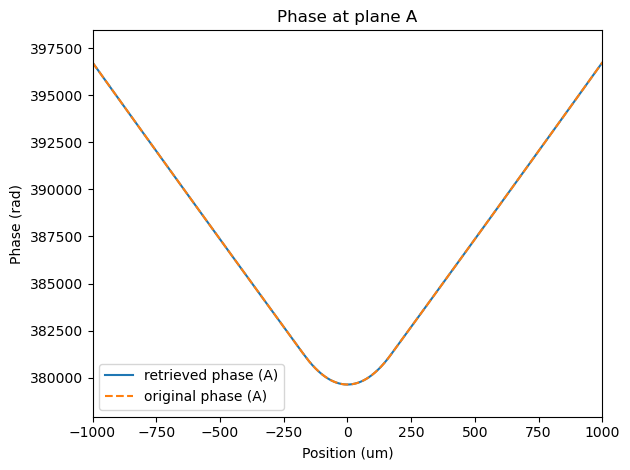

In [ ]:
phase_ret = np.unwrap(np.angle(recon_A))

plt.plot(x_m*1e6, phase_ret, label='retrieved phase (A)')
try:
    orig_phase_A = np.unwrap(np.angle(E_z[:, idx_A]))
    plt.plot(x_m*1e6, orig_phase_A, '--', label='original phase (A)')
except Exception:
    pass

plt.xlim(-1000, 1000)

# Auto-tighten y bounds to match only the visible x region (-1000 to 1000 um)
mask = (x_m * 1e6 >= -1000) & (x_m * 1e6 <= 1000)
y_min = np.min(phase_ret[mask])
y_max = np.max(phase_ret[mask])
pad = 0.1 * (y_max - y_min) if y_max != y_min else 1.0  # 10% padding
plt.ylim(y_min - pad, y_max + pad)

plt.xlabel('Position (um)')
plt.ylabel('Phase (rad)')
plt.title('Phase at plane A')
plt.legend()

plt.tight_layout()
plt.show()